<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/UTS/dbscan_cosine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DBSCAN - Cosine


In [1]:
import time
import tracemalloc
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler, Normalizer

# Lokasi data/output: berjalan dari root repo, machine_learning, atau experiments.
# Notebook tidak menyediakan __file__.
cwd = Path.cwd().resolve()
BASE_DIR = next(
    (base for parent in (cwd, *cwd.parents)
     for base in (parent / "machine_learning", parent)
     if (base / "experiments").is_dir() and (base / "data").is_dir()),
    None,
)
from pathlib import Path

DATA_PATH = Path("/content/cafes.csv")
FIGURES_DIR = Path("/content/reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
# ==============================================================================
# BAGIAN A: LOAD DATA & PREPROCESSING
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN A: LOAD DATA & PREPROCESSING (DBSCAN)")
print("="*56)

df = pd.read_csv(DATA_PATH, on_bad_lines="skip")
kolom_fitur = ['latitude', 'longitude', 'rating', 'review_count']
kolom_ada = [k for k in kolom_fitur if k in df.columns]
df_fitur = df[kolom_ada].dropna()

# Standardisasi fitur numerik
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_fitur)

# L2 Normalization — WAJIB untuk Cosine distance (persis DBScan_Cosine.ipynb)
normalizer = Normalizer(norm='l2')
X_l2 = normalizer.fit_transform(X_scaled)

print(f"Data siap | Shape: {X_scaled.shape} | Baris: {len(df_fitur)}")
print("L2 Normalization diterapkan untuk Cosine distance.")



  BAGIAN A: LOAD DATA & PREPROCESSING (DBSCAN)
Data siap | Shape: (99, 4) | Baris: 99
L2 Normalization diterapkan untuk Cosine distance.



  BAGIAN B: K-DISTANCE GRAPH (KNN UNTUK TUNING EPS)


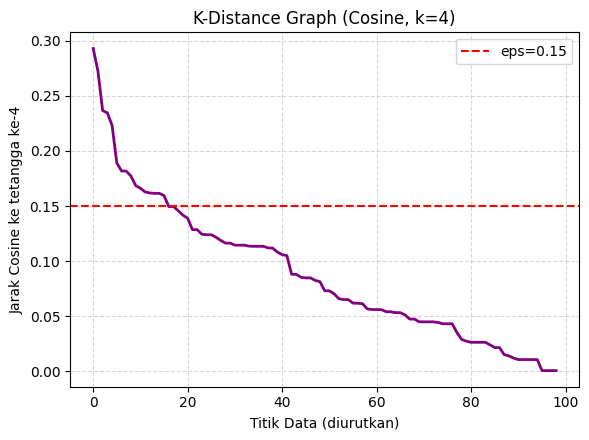

K-distance graph disimpan: /content/reports/figures/dbscan_cosine_kdistance_plots.png


In [3]:
# ==============================================================================
# BAGIAN B: K-DISTANCE GRAPH (UNTUK MENENTUKAN EPSILON OPTIMAL)
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN B: K-DISTANCE GRAPH (KNN UNTUK TUNING EPS)")
print("="*56)

# Nilai min_samples acuan untuk estimasi eps
K_NEIGHBORS = 4

# 3. K-Distance Cosine
nn_c = NearestNeighbors(n_neighbors=K_NEIGHBORS, metric='cosine').fit(X_l2)
d_c, _ = nn_c.kneighbors(X_l2)
kdist_c = np.sort(d_c[:, -1])[::-1]
EPS_COS = 0.15

plt.figure(figsize=(6, 4.5))
plt.plot(kdist_c, color='purple', linewidth=2)
plt.axhline(y=EPS_COS, color='red', linestyle='--', linewidth=1.5, label=f'eps={EPS_COS}')
plt.title(f'K-Distance Graph (Cosine, k={K_NEIGHBORS})')
plt.xlabel('Titik Data (diurutkan)')
plt.ylabel(f'Jarak Cosine ke tetangga ke-{K_NEIGHBORS}')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
kdist_plot_path = FIGURES_DIR / "dbscan_cosine_kdistance_plots.png"
plt.savefig(kdist_plot_path, dpi=150)
plt.show()
plt.close()
print(f"K-distance graph disimpan: {kdist_plot_path}")


In [4]:
# --- 3. DBSCAN COSINE ---
print("\n" + "="*56)
print("  DBSCAN — METRIK: COSINE")
print(f"  Parameter: eps={EPS_COS}, min_samples={K_NEIGHBORS}")
print("="*56)

tracemalloc.start()
t_mulai = time.time()

db_cosine = DBSCAN(eps=EPS_COS, min_samples=K_NEIGHBORS, metric='cosine')
lbl_cosine = db_cosine.fit_predict(X_l2)

t_selesai = time.time()
_, mem_puncak = tracemalloc.get_traced_memory()
tracemalloc.stop()

n_klaster_c = len(set(lbl_cosine)) - (1 if -1 in lbl_cosine else 0)
n_noise_c = int((lbl_cosine == -1).sum())
pct_noise_c = n_noise_c / len(lbl_cosine) * 100
mask_valid_c = lbl_cosine != -1

if mask_valid_c.sum() > 1 and n_klaster_c >= 2:
    sil_cosine = silhouette_score(X_l2[mask_valid_c], lbl_cosine[mask_valid_c], metric='cosine')
    sil_c_str = f"{sil_cosine:.4f}"
else:
    sil_cosine = None
    sil_c_str = "N/A (klaster < 2)"

waktu_c = t_selesai - t_mulai
mem_c_kb = mem_puncak / 1024
mem_c_mb = mem_puncak / (1024**2)

print(f"  Jumlah Klaster    : {n_klaster_c}")
print(f"  Titik Noise (-1)  : {n_noise_c} ({pct_noise_c:.1f}%)")
print(f"  Waktu Eksekusi    : {waktu_c:.4f} detik")
print(f"  Memori Puncak     : {mem_c_kb:.2f} KB ({mem_c_mb:.4f} MB)")
print(f"  Silhouette Score  : {sil_c_str}")
print("="*56)



  DBSCAN — METRIK: COSINE
  Parameter: eps=0.15, min_samples=4
  Jumlah Klaster    : 5
  Titik Noise (-1)  : 4 (4.0%)
  Waktu Eksekusi    : 0.0061 detik
  Memori Puncak     : 168.83 KB (0.1649 MB)
  Silhouette Score  : 0.3228



  BAGIAN D: VISUALISASI PCA 2D (DBSCAN)


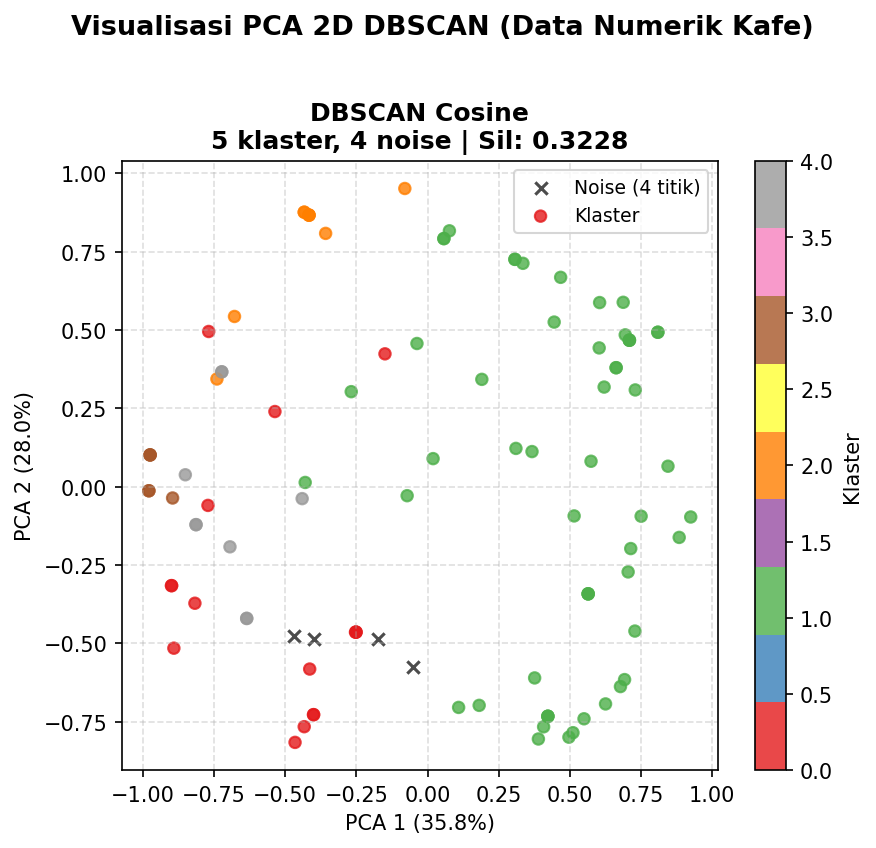

Visualisasi PCA disimpan ke: /content/reports/figures/dbscan_cosine_pca_plots.png


In [5]:
# ==============================================================================
# BAGIAN D: VISUALISASI PCA 2D DENGAN TITIK NOISE HITAM (X)
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN D: VISUALISASI PCA 2D (DBSCAN)")
print("="*56)

pca_l2 = PCA(n_components=2, random_state=42)
X_pca_l2 = pca_l2.fit_transform(X_l2)
v1_l2, v2_l2 = pca_l2.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(6, 5.5), dpi=150)
axes = [ax]

# Helper untuk plot DBSCAN PCA (mengadaptasi cell visualisasi DBScan kuis_01)
def plot_dbscan_pca(ax, X_pca_coords, lbls, v1, v2, title):
    mask_noise = lbls == -1
    mask_klaster = ~mask_noise

    # Plot titik noise -> hitam, tanda x
    ax.scatter(X_pca_coords[mask_noise, 0], X_pca_coords[mask_noise, 1],
               c='black', marker='x', s=35, alpha=0.7,
               label=f'Noise ({mask_noise.sum()} titik)')

    # Plot titik klaster -> berwarna
    if mask_klaster.sum() > 0:
        sc = ax.scatter(X_pca_coords[mask_klaster, 0], X_pca_coords[mask_klaster, 1],
                        c=lbls[mask_klaster], cmap='Set1', s=30, alpha=0.8,
                        label='Klaster')
        plt.colorbar(sc, ax=ax, label='Klaster')

    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(f'PCA 1 ({v1:.1f}%)')
    ax.set_ylabel(f'PCA 2 ({v2:.1f}%)')
    ax.legend(fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.4)

plot_dbscan_pca(axes[0], X_pca_l2, lbl_cosine, v1_l2, v2_l2,
                f"DBSCAN Cosine\n{n_klaster_c} klaster, {n_noise_c} noise | Sil: {sil_c_str}")

plt.suptitle("Visualisasi PCA 2D DBSCAN (Data Numerik Kafe)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
dbscan_pca_path = FIGURES_DIR / "dbscan_cosine_pca_plots.png"
plt.savefig(dbscan_pca_path, dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print(f"Visualisasi PCA disimpan ke: {dbscan_pca_path}")


In [6]:
# Dictionary ringkasan performa untuk pelaporan
DBSCAN_SUMMARY = {
    "cosine": {
        "algo": "DBSCAN", "metric": "Cosine", "param": f"eps={EPS_COS}, ms={K_NEIGHBORS}",
        "time": waktu_c, "mem_mb": mem_c_mb, "clusters": n_klaster_c,
        "noise_pct": pct_noise_c, "silhouette": sil_cosine, "labels": lbl_cosine
    }
}
